# Lesson 7 — Experiments: what makes the model better?

⏱ **Duration:** ~20 min &nbsp;|&nbsp; 📚 **Builds on:** Lesson 6 &nbsp;|&nbsp; 💻 **Runs on:** a laptop CPU

**By the end of this lesson you will be able to:**

- run controlled experiments with a fixed time budget
- compare models by validation loss, speed and size
- draw conclusions about size, context and compute

> 🎤 *Teaching tip:* run the cells in order; every code cell is short enough to be explained live.

## 1. Scientific method for ML

Change **one thing at a time**, keep everything else (data, seed, time budget) fixed, and compare on the
same validation data. Here every run gets **40 seconds**, so a bigger model gets *fewer* steps — exactly the trade-off
you face on a real machine.

Experiments:

| name | change vs. baseline |
|------|---------------------|
| `baseline` | tiny preset: 2 layers, 64 wide, context 32 |
| `wider` | 128 wide (more capacity, slower) |
| `longer-context` | context 64 instead of 32 |

In [1]:
import sys, warnings
from pathlib import Path

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))  # lets us `import myllm` without installing it

import torch
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
torch.set_num_threads(4)
DATA = ROOT / "data" / "raw"       # training text lives here
MODELS = ROOT / "models"           # checkpoints are written here

In [2]:
import math, json
from myllm.train import PRESETS, TrainConfig, train, history_path_for

base_kw, base_defaults, _ = PRESETS["tiny"]
PRESETS["exp_baseline"] = (dict(base_kw), dict(base_defaults), 1.0)
PRESETS["exp_wider"] = (dict(base_kw, n_embd=128, n_head=4), dict(base_defaults), 1.0)
PRESETS["exp_longer"] = (dict(base_kw, block_size=64), dict(base_defaults), 1.0)
EXP = MODELS / "experiments"; EXP.mkdir(parents=True, exist_ok=True)

## 2. Run the experiments (≈ 2 minutes)

In [3]:
results = {}
for name in ("baseline", "wider", "longer"):
    print(f"\n===== {name} =====")
    cfg = TrainConfig(preset=f"exp_{name}", minutes=40 / 60, eval_every=100, log=False)
    res = train(DATA, EXP / f"{name}.pt", cfg)
    results[name] = res
    print(f"{res.steps} steps, val loss {res.val_loss:.3f}, ppl {math.exp(res.val_loss):.1f}")


===== baseline =====
1327 steps, val loss 3.974, ppl 53.2

===== wider =====
713 steps, val loss 4.021, ppl 55.8

===== longer =====
709 steps, val loss 4.158, ppl 63.9


## 3. Compare

In [4]:
print(f"{'run':10s} {'params':>9s} {'steps':>6s} {'tok/s':>7s} {'val loss':>9s} {'val ppl':>8s}")
for k, r in results.items():
    print(f"{k:10s} {r.n_params:9,d} {r.steps:6d} {r.timings['tokens_per_s']:7.0f} {r.val_loss:9.4f} {math.exp(r.val_loss):8.2f}")

run           params  steps   tok/s  val loss  val ppl
baseline     230,144   1327   16902    3.9743    53.21
wider        656,896    713    9067    4.0212    55.77
longer       232,192    709   18034    4.1576    63.92


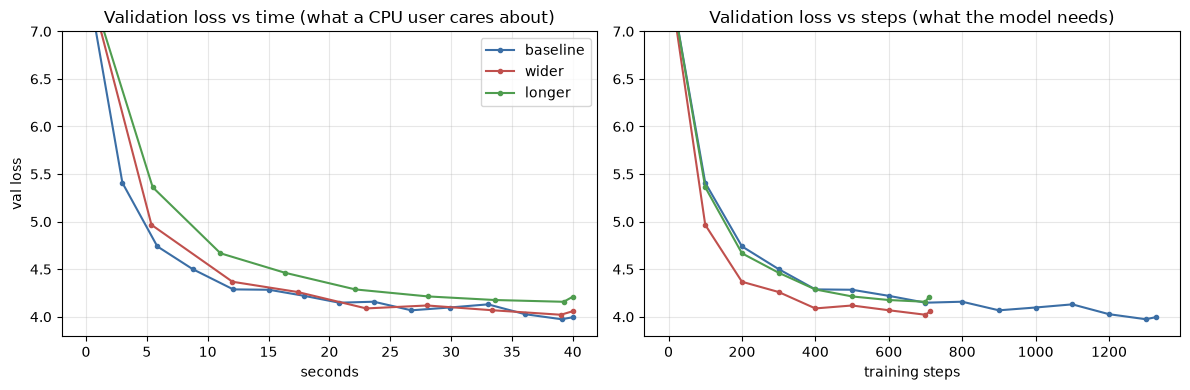

In [5]:
colors = {"baseline": "#3b6ea5", "wider": "#c0504d", "longer": "#4f9d4f"}
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, r in results.items():
    h = [p for p in r.history]
    ax[0].plot([p["seconds"] for p in h], [p["val_loss"] for p in h], "o-", ms=3, label=name, color=colors[name])
    ax[1].plot([p["step"] for p in h], [p["val_loss"] for p in h], "o-", ms=3, label=name, color=colors[name])
ax[0].set(title="Validation loss vs time (what a CPU user cares about)", xlabel="seconds", ylabel="val loss", ylim=(None, 7))
ax[1].set(title="Validation loss vs steps (what the model needs)", xlabel="training steps", ylim=(None, 7))
ax[0].legend(); plt.tight_layout()

## 4. Reading the experiment

Compare the two charts:

* **vs. steps** — bigger/wider models usually learn *more per step*.
* **vs. time** — they also cost *more per step*, so with a fixed budget the advantage may shrink or vanish.

> ⚖️ **A tie is a result too.** The wider model does half as many steps in the same time and ends at about the
> same loss: more capacity per step, fewer steps. Differences smaller than the run-to-run noise (exercise 1) mean nothing.

> 💬 **Discussion questions for the class**
> 1. Which variant won on validation loss? Is the difference larger than run-to-run noise? (How would you check? → exercise 1)
> 2. A longer context makes each step slower. Did it pay off in 40 seconds?
> 3. What would change with a 10× larger time budget? (→ lesson 8)

---
## ✅ Key takeaways

- Fair comparison = same data, same seed, same budget, one change at a time.
- With a fixed compute budget, a bigger model is not automatically better: steps matter as much as capacity.
- Report loss against *time* and against *steps*; they tell different stories.

## 🧪 Exercises

1. Re-run with a different `seed` in `TrainConfig`. How much does the validation loss move for the *same* model? Use that as your noise level.
2. Add an experiment `deeper` (4 layers). Where does it land?
3. Try `lr=3e-3` and `lr=3e-4` for the baseline. Is 1e-3 a good default?

## ➡️ Next

**Lesson 8 — The 10-minute LLM:** put everything together with the full-size preset.